# 2.1 CÂY QUYẾT ĐỊNH VÀ RỪNG NGẪU NHIÊN (DECISION TREE & RANDOM FOREST)
### Học phần: Máy học (DCT124C1)
### Thành viên phụ trách: Lê Văn Hiếu (Nhóm trưởng - Thành viên 1)

Nội dung thực hiện:
- **2.1.1. Ôn tập lý thuyết:** Trả lời chi tiết 9 câu hỏi trọng tâm về CRISP-DM, SEMMA, cấu trúc cây quyết định, các chỉ số Gini/Entropy/Information Gain, Random Forest, Feature Importance và Hyperparameter Tuning.
- **2.1.2. Bài làm mẫu:** Dự đoán khả năng vỡ nợ thẻ tín dụng (Credit Card Clients) theo kịch bản giáo trình:
  - Nhiệm vụ 1: Nạp dữ liệu, loại bỏ cột không liên quan, huấn luyện DecisionTreeClassifier(max_depth=2), xuất đồ thị cây.
  - Nhiệm vụ 2: GridSearchCV tìm max_depth tối ưu, vẽ biểu đồ errorbar Mean +- 1 SE.
  - Nhiệm vụ 3: RandomForestClassifier tuning n_estimators, vẽ subplot 1x2 và Feature Importance.
- **2.1.3. Bài tập thực hành 1:** Dự đoán khả năng sống sót trên tàu Titanic (EDA, Baseline, GridSearchCV, Ma trận nhầm lẫn, Feature Importance, phân tích quá khớp).
- **2.1.4. Bài tập thực hành 2:** Dự đoán bệnh tiểu đường Pima Indians (xử lý giá trị 0 bất thường, Baseline, GridSearchCV, đánh giá đa thước đo, phân tích quá khớp).


## 2.1.1. ÔN TẬP LÝ THUYẾT

### Câu 1.
Quy trình CRISP-DM gồm 6 giai đoạn: Thấu hiểu nghiệp vụ, Thấu hiểu dữ liệu, Chuẩn bị dữ liệu, Xây dựng mô hình, Đánh giá, Triển khai. Đây là quy trình có tính chu kỳ, kết quả giai đoạn sau có thể quay vòng bổ sung cho giai đoạn trước.
Quy trình SEMMA của SAS gồm 5 bước kỹ thuật: Sample, Explore, Modify, Model, Assess.
Khác biệt: CRISP-DM bao quát toàn bộ vòng đời dự án từ bài toán thực tế đến triển khai vào sản xuất. SEMMA tập trung chủ yếu vào các bước kỹ thuật xử lý dữ liệu và huấn luyện mô hình, không có bước thấu hiểu nghiệp vụ ban đầu và bước triển khai thực tế.

### Câu 2.
Cây quyết định hoạt động theo nguyên lý chia để trị, phân chia không gian dữ liệu thành các vùng thuần khiết hơn bằng các câu hỏi điều kiện trên từng thuộc tính.
- Nút gốc: Nút cao nhất, chứa toàn bộ dữ liệu ban đầu, chọn thuộc tính có lực phân tách tốt nhất để chia đôi tập mẫu.
- Nút nhánh: Nút trung gian kiểm tra điều kiện trên một thuộc tính cụ thể và tiếp tục phân nhánh con.
- Nút lá: Nút kết thúc không chia thêm, chứa nhãn dự đoán cho phân loại hoặc giá trị trung bình cho hồi quy.
Cơ chế dự đoán: Mẫu mới bắt đầu từ nút gốc, so sánh giá trị thuộc tính với ngưỡng điều kiện để rẽ nhánh tương ứng cho đến khi chạm nút lá. Nhãn của nút lá chính là kết quả dự đoán.

### Câu 3.
- Chỉ số Gini: Gini đo xác suất một phần tử bị gán sai nhãn khi gán ngẫu nhiên theo phân bố trong nút. Nút thuần khiết có Gini bằng 0.
- Entropy: Entropy đo mức độ hỗn loạn thông tin. Nút thuần khiết có Entropy bằng 0, nút cân bằng có Entropy cực đại.
- Information Gain: Đo mức độ giảm độ hỗn loạn thông tin sau khi chia tập dữ liệu theo thuộc tính.
Khác biệt: Gini tính toán nhanh hơn vì chỉ gồm phép nhân bình phương, không cần tính logarit như Entropy. CART dùng Gini làm mặc định, còn ID3 và C4.5 dùng Entropy.

### Câu 4.
Random Forest là mô hình học kết hợp xây dựng từ một tập hợp gồm nhiều cây quyết định độc lập.
Khác biệt: Cây quyết định đơn lẻ dùng toàn bộ dữ liệu và xét toàn bộ đặc trưng tại mỗi điểm cắt, rất dễ ghi nhớ mẫu nhiễu và bị quá khớp. Random Forest huấn luyện mỗi cây trên một tập con lấy ngẫu nhiên có hoàn lại từ tập huấn luyện và tại mỗi nút chỉ xét một tập con ngẫu nhiên các đặc trưng.
Hiệu suất cao hơn và giảm quá khớp: Các cây đơn lẻ có phương sai cao nhưng độ chệch thấp. Do được tạo ngẫu nhiên, các cây con ít tương quan với nhau. Khi lấy trung bình hoặc bỏ phiếu đa số, phương sai tổng thể giảm mạnh theo quy luật số lớn trong khi độ chệch vẫn thấp, giúp mô hình tổng quát hóa tốt hơn.

### Câu 5.
- Decision Tree: Ưu điểm là trực quan, dễ giải thích, không yêu cầu chuẩn hóa thang đo dữ liệu, xử lý tốt cả biến số và phân loại. Hạn chế là rất dễ bị quá khớp nếu cây quá sâu, nhạy cảm với biến động nhỏ của dữ liệu. Cây hoạt động kém khi dữ liệu có nhiều biến liên tục tương quan chéo phức tạp hoặc tập dữ liệu chứa nhiều mẫu nhiễu.
- Random Forest: Ưu điểm là hiệu năng phân loại cao, kháng quá khớp tốt, hoạt động ổn định trên dữ liệu nhiều chiều và đo lường được độ quan trọng của đặc trưng. Hạn chế là cấu trúc hộp đen khó diễn giải trực tiếp, tốn tài nguyên tính toán và thời gian dự đoán chậm hơn cây đơn lẻ.

### Câu 6.
Code mẫu Python với Scikit-learn xây dựng cây quyết định:


In [1]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Nap du lieu
iris = load_iris()
X, y = iris.data, iris.target

# 2. Chia tap du lieu 80% train va 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Khoi tao DecisionTreeClassifier voi do sau toi da bang 3
model = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)

# 4. Huan luyen mo hinh
model.fit(X_train, y_train)

# 5. Du doan va danh gia
y_pred = model.predict(X_test)
print('Accuracy:', accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=iris.target_names))


Accuracy: 0.9666666666666667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



### Câu 7.
Các siêu tham số chính trong RandomForestClassifier:
- n_estimators: Tổng số cây quyết định trong rừng. Số cây càng nhiều thì kết quả càng ổn định nhưng thời gian tính toán tăng tỉ lệ thuận.
- max_depth: Chiều sâu tối đa của mỗi cây. Khống chế độ sâu giúp ngăn từng cây con bị quá khớp.
- max_features: Số lượng đặc trưng ngẫu nhiên tối đa được chọn để tìm điểm phân tách tại mỗi nút. Thường chọn căn bậc hai của tổng số đặc trưng.
- min_samples_split: Số lượng mẫu tối thiểu cần thiết tại một nút để được phép tiếp tục phân chia nhánh.
- min_samples_leaf: Số lượng mẫu tối thiểu bắt buộc phải có tại mỗi nút lá.


In [2]:
from sklearn.ensemble import RandomForestClassifier

rf_example = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    max_features='sqrt',
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42
)
rf_example.fit(X_train, y_train)
print('Random Forest Accuracy:', rf_example.score(X_test, y_test))


Random Forest Accuracy: 0.9666666666666667


### Câu 8.
Đánh giá và trực quan hóa Feature Importance trong Random Forest bằng Python:


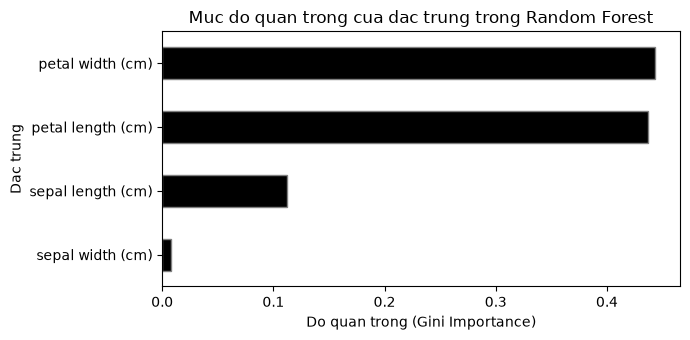

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

importances = pd.Series(rf_example.feature_importances_, index=iris.feature_names)
importances_sorted = importances.sort_values(ascending=True)

plt.figure(figsize=(7, 3.5))
importances_sorted.plot(kind='barh', color='black', edgecolor='gray')
plt.xlabel('Do quan trong (Gini Importance)')
plt.ylabel('Dac trung')
plt.title('Muc do quan trong cua dac trung trong Random Forest')
plt.tight_layout()
plt.show()


### Câu 9.
Điều chỉnh siêu tham số bằng GridSearchCV và RandomizedSearchCV:
- GridSearchCV duyệt vét cạn qua tất cả các tổ hợp siêu tham số được định nghĩa trong lưới tham số, đảm bảo tìm được cấu hình tốt nhất trong lưới nhưng tốn thời gian tính toán.
- RandomizedSearchCV chọn ngẫu nhiên một số lượng cấu hình cố định từ không gian tham số, tiết kiệm đáng kể thời gian và phù hợp khi cần khảo sát diện rộng.


In [4]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [3, 5],
    'min_samples_split': [2, 5]
}

# GridSearchCV
grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=3, scoring='accuracy')
grid.fit(X_train, y_train)
print('GridSearchCV Best params:', grid.best_params_)

# RandomizedSearchCV
random_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42), param_grid, n_iter=4, cv=3, scoring='accuracy', random_state=42
)
random_search.fit(X_train, y_train)
print('RandomizedSearchCV Best params:', random_search.best_params_)


GridSearchCV Best params: {'max_depth': 3, 'min_samples_split': 2, 'n_estimators': 50}
RandomizedSearchCV Best params: {'n_estimators': 100, 'min_samples_split': 2, 'max_depth': 3}


---
## 2.1.2. BÀI LÀM MẪU: DỰ ĐOÁN KHẢ NĂNG VỠ NỢ THẺ TÍN DỤNG (CREDIT CARD CLIENTS)

### Nhiệm vụ 1: Nạp dữ liệu, loại bỏ cột không liên quan, huấn luyện DecisionTreeClassifier(max_depth=2) và xuất đồ thị cây


Kich thuoc du lieu goc: (30000, 25)
So luong dac trung giu lai: 17
Danh sach dac trung: ['LIMIT_BAL', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_1', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']
X_train: (24000, 17) X_test: (6000, 17)
DecisionTree (max_depth=2) Test ROC AUC: 0.7028
Graphviz fallback: failed to execute WindowsPath('dot'), make sure the Graphviz executables are on your systems' PATH


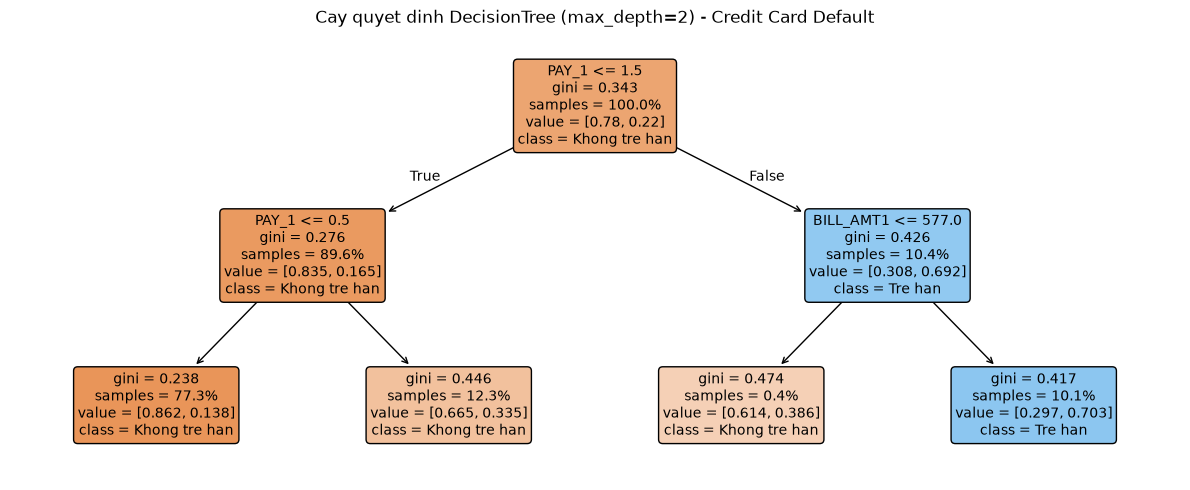

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_graphviz
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

# Xac dinh duong dan file du lieu
data_path = '../data/default_of_credit_card_clients.csv' if os.path.exists('../data/default_of_credit_card_clients.csv') else 'Lab05_ThucHanhBaiToanPhanLop/data/default_of_credit_card_clients.csv'
df_cc = pd.read_csv(data_path)
print('Kich thuoc du lieu goc:', df_cc.shape)

# Chuan hoa PAY_0 thanh PAY_1 neu co
if 'PAY_0' in df_cc.columns:
    df_cc = df_cc.rename(columns={'PAY_0': 'PAY_1'})

# Loai bo cac cot khong lien quan: ID, SEX, PAY_2 den PAY_6
cols_to_drop = ['ID', 'SEX', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
df_clean = df_cc.drop(columns=[c for c in cols_to_drop if c in df_cc.columns])

target_col = 'default payment next month'
X_cc = df_clean.drop(columns=[target_col])
y_cc = df_clean[target_col]
feature_names_cc = list(X_cc.columns)
print('So luong dac trung giu lai:', len(feature_names_cc))
print('Danh sach dac trung:', feature_names_cc)

# Chia train/test 80/20 voi test_size=0.2, random_state=24
X_train_cc, X_test_cc, y_train_cc, y_test_cc = train_test_split(
    X_cc, y_cc, test_size=0.2, random_state=24
)
print('X_train:', X_train_cc.shape, 'X_test:', X_test_cc.shape)

# Huan luyen DecisionTreeClassifier(max_depth=2)
dt2 = DecisionTreeClassifier(max_depth=2, random_state=24)
dt2.fit(X_train_cc, y_train_cc)

# Tinh ROC AUC tren tap test
y_prob_dt2 = dt2.predict_proba(X_test_cc)[:, 1]
print('DecisionTree (max_depth=2) Test ROC AUC:', round(roc_auc_score(y_test_cc, y_prob_dt2), 4))

# Xuat do thi cay quyet dinh (graphviz va fallback plot_tree voi dpi=400)
try:
    import graphviz
    dot_data = export_graphviz(
        dt2, out_file=None, feature_names=feature_names_cc,
        class_names=['Khong tre han', 'Tre han'], filled=True, rounded=True, proportion=True
    )
    graph = graphviz.Source(dot_data)
    graph.render('../figures/2_1_2_decision_tree_depth2', format='png', cleanup=True)
    print("Xuat cay bang graphviz thanh cong.")
except Exception as e:
    print('Graphviz fallback:', e)
    plt.figure(figsize=(12, 5), dpi=400)
    plot_tree(
        dt2, feature_names=feature_names_cc,
        class_names=['Khong tre han', 'Tre han'], filled=True, rounded=True, fontsize=10, proportion=True
    )
    plt.title("Cay quyet dinh DecisionTree (max_depth=2) - Credit Card Default")
    plt.tight_layout()
    plt.savefig('../figures/2_1_2_decision_tree_depth2.png', dpi=400, bbox_inches='tight')
    plt.show()


### Nhiệm vụ 2: Dùng GridSearchCV tìm max_depth trong [1, 2, 4, 6, 8, 10, 12] và vẽ biểu đồ errorbar Mean +- 1 SE
- `scoring='roc_auc'`: Đo lường diện tích dưới đường cong ROC, phù hợp với dữ liệu mất cân bằng nhãn.
- `cv=4`: Kiểm định chéo 4-fold chia tập huấn luyện thành 4 phần bằng nhau, luân phiên 3 phần huấn luyện và 1 phần kiểm định.
- `return_train_score=True`: Cho phép lưu lại kết quả đánh giá trên cả tập train để phát hiện hiện tượng quá khớp (overfitting).


Best max_depth: 6
Best CV ROC AUC: 0.7441


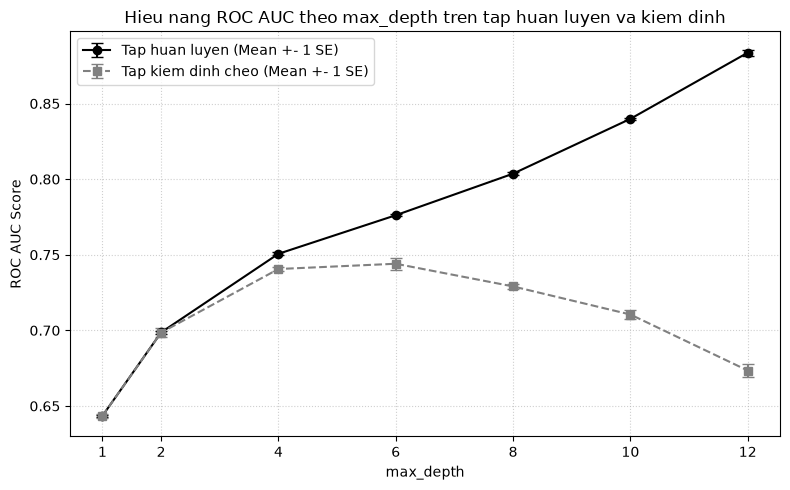

In [6]:
param_grid_dt = {'max_depth': [1, 2, 4, 6, 8, 10, 12]}
dt_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=24),
    param_grid=param_grid_dt,
    scoring='roc_auc',
    cv=4,
    return_train_score=True
)
dt_search.fit(X_train_cc, y_train_cc)

print('Best max_depth:', dt_search.best_params_['max_depth'])
print('Best CV ROC AUC:', round(dt_search.best_score_, 4))

# Tinh toan Mean +- 1 SE cho train va test
cv_res = pd.DataFrame(dt_search.cv_results_)
mean_tr = cv_res['mean_train_score']
se_tr = cv_res['std_train_score'] / np.sqrt(4)
mean_te = cv_res['mean_test_score']
se_te = cv_res['std_test_score'] / np.sqrt(4)

plt.figure(figsize=(8, 5))
plt.errorbar(
    param_grid_dt['max_depth'], mean_tr, yerr=se_tr,
    fmt='-o', color='black', label='Tap huan luyen (Mean +- 1 SE)', capsize=4
)
plt.errorbar(
    param_grid_dt['max_depth'], mean_te, yerr=se_te,
    fmt='--s', color='gray', label='Tap kiem dinh cheo (Mean +- 1 SE)', capsize=4
)
plt.xlabel('max_depth')
plt.ylabel('ROC AUC Score')
plt.title('Hieu nang ROC AUC theo max_depth tren tap huan luyen va kiem dinh')
plt.xticks(param_grid_dt['max_depth'])
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig('../figures/2_1_2_dt_max_depth_errorbar.png', dpi=300, bbox_inches='tight')
plt.show()


### Nhiệm vụ 3: Khởi tạo RandomForestClassifier(max_depth=3, max_features='sqrt', random_state=4), GridSearchCV n_estimators từ 10 đến 100
- Vẽ subplot 1x2: Mean fit time và Mean testing ROC AUC +- 1 SE.
- In best_params_ và vẽ biểu đồ thanh ngang barh cho feature_importances_.


Random Forest Best params: {'n_estimators': 60}
Random Forest Best CV ROC AUC: 0.7616
Random Forest Best Test ROC AUC: 0.7656


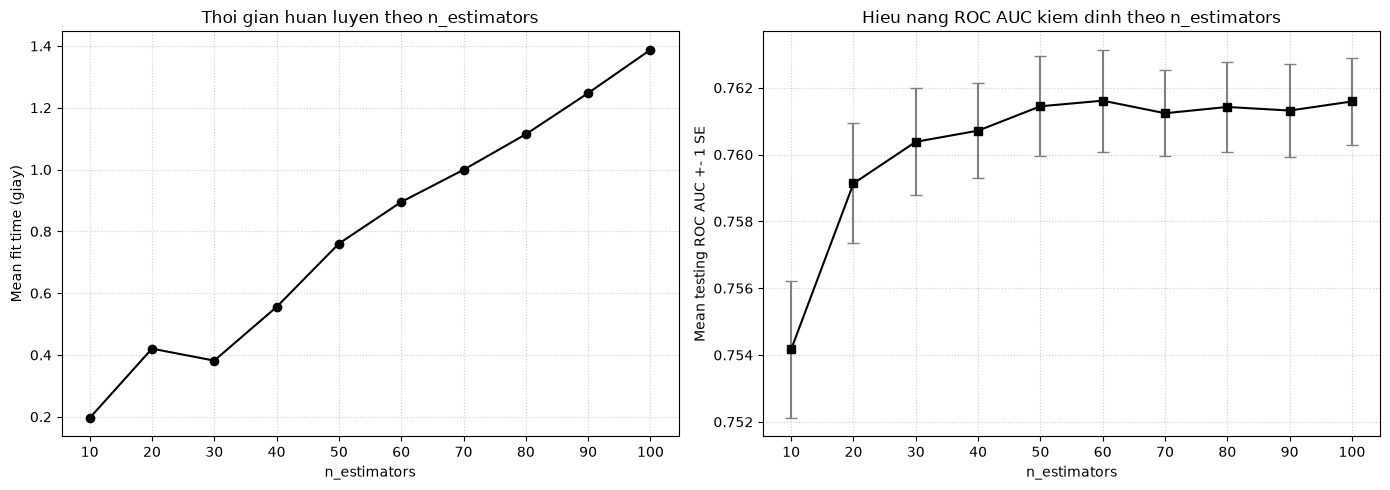

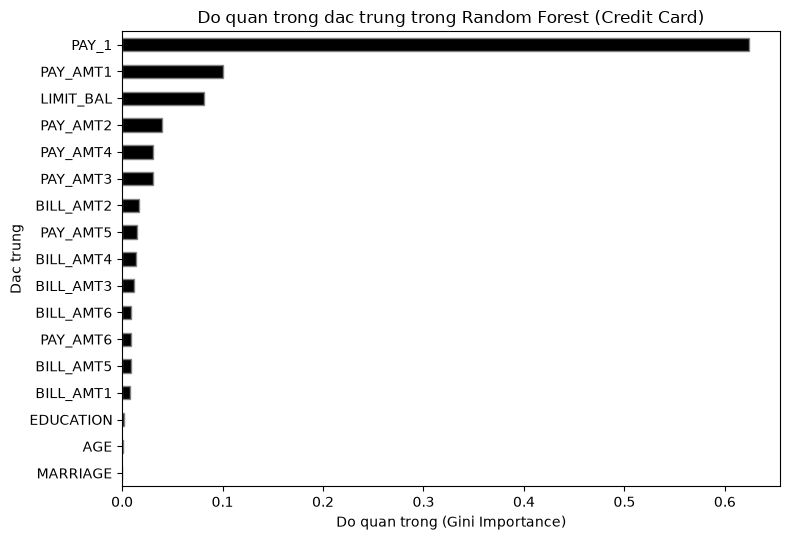

In [7]:
param_grid_rf = {'n_estimators': list(range(10, 101, 10))}
rf_search = GridSearchCV(
    estimator=RandomForestClassifier(max_depth=3, max_features='sqrt', random_state=4),
    param_grid=param_grid_rf,
    scoring='roc_auc',
    cv=4,
    return_train_score=True
)
rf_search.fit(X_train_cc, y_train_cc)

print('Random Forest Best params:', rf_search.best_params_)
print('Random Forest Best CV ROC AUC:', round(rf_search.best_score_, 4))

cv_res_rf = pd.DataFrame(rf_search.cv_results_)
mean_time = cv_res_rf['mean_fit_time']
mean_te_rf = cv_res_rf['mean_test_score']
se_te_rf = cv_res_rf['std_test_score'] / np.sqrt(4)

# Subplot 1x2
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(param_grid_rf['n_estimators'], mean_time, '-o', color='black')
axes[0].set_xlabel('n_estimators')
axes[0].set_ylabel('Mean fit time (giay)')
axes[0].set_title('Thoi gian huan luyen theo n_estimators')
axes[0].set_xticks(param_grid_rf['n_estimators'])
axes[0].grid(True, linestyle=':', alpha=0.6)

axes[1].errorbar(
    param_grid_rf['n_estimators'], mean_te_rf, yerr=se_te_rf,
    fmt='-s', color='black', ecolor='gray', capsize=4
)
axes[1].set_xlabel('n_estimators')
axes[1].set_ylabel('Mean testing ROC AUC +- 1 SE')
axes[1].set_title('Hieu nang ROC AUC kiem dinh theo n_estimators')
axes[1].set_xticks(param_grid_rf['n_estimators'])
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('../figures/2_1_2_rf_n_estimators_tuning.png', dpi=300, bbox_inches='tight')
plt.show()

# Feature Importances barh
best_rf_cc = rf_search.best_estimator_
fi_cc = pd.Series(best_rf_cc.feature_importances_, index=feature_names_cc).sort_values(ascending=True)

plt.figure(figsize=(8, 5.5))
fi_cc.plot(kind='barh', color='black', edgecolor='gray')
plt.xlabel('Do quan trong (Gini Importance)')
plt.ylabel('Dac trung')
plt.title('Do quan trong dac trung trong Random Forest (Credit Card)')
plt.tight_layout()
plt.savefig('../figures/2_1_2_rf_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

# Danh gia test ROC AUC
test_auc_rf_cc = roc_auc_score(y_test_cc, best_rf_cc.predict_proba(X_test_cc)[:, 1])
print('Random Forest Best Test ROC AUC:', round(test_auc_rf_cc, 4))


---
## 2.1.3. BÀI TẬP THỰC HÀNH 1: DỰ ĐOÁN KHẢ NĂNG SỐNG SÓT TRÊN TÀU TITANIC

### 1. Khám phá & Tiền xử lý dữ liệu Titanic


In [8]:
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

ti_path = '../data/train.csv' if os.path.exists('../data/train.csv') else 'Lab05_ThucHanhBaiToanPhanLop/data/train.csv'
titanic_raw = pd.read_csv(ti_path)
print('Kich thuoc Titanic goc:', titanic_raw.shape)
print('Phan bo nhan Survived:')
print(titanic_raw['Survived'].value_counts())
print('Gia tri khuyet thieu:')
print(titanic_raw.isna().sum()[titanic_raw.isna().sum() > 0])

# Tien xu ly khong ro ri du lieu
ti_df = titanic_raw.copy()
ti_df['Sex'] = ti_df['Sex'].map({'male': 0, 'female': 1})
features_raw = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
X_raw = ti_df[features_raw]
y = ti_df['Survived']

X_tr_ti, X_te_ti, y_tr_ti, y_te_ti = train_test_split(
    X_raw, y, test_size=0.2, random_state=42, stratify=y
)
X_tr_ti = X_tr_ti.copy()
X_te_ti = X_te_ti.copy()

age_med = X_tr_ti['Age'].median()
emb_mode = X_tr_ti['Embarked'].mode()[0]
X_tr_ti['Age'] = X_tr_ti['Age'].fillna(age_med)
X_te_ti['Age'] = X_te_ti['Age'].fillna(age_med)
X_tr_ti['Embarked'] = X_tr_ti['Embarked'].fillna(emb_mode)
X_te_ti['Embarked'] = X_te_ti['Embarked'].fillna(emb_mode)

X_tr_ti = pd.get_dummies(X_tr_ti, columns=['Embarked'], drop_first=True, dtype=int)
X_te_ti = pd.get_dummies(X_te_ti, columns=['Embarked'], drop_first=True, dtype=int)
X_te_ti = X_te_ti.reindex(columns=X_tr_ti.columns, fill_value=0)
features_ti = list(X_tr_ti.columns)

print('X_train:', X_tr_ti.shape, 'X_test:', X_te_ti.shape)


Kich thuoc Titanic goc: (891, 12)
Phan bo nhan Survived:
Survived
0    549
1    342
Name: count, dtype: int64
Gia tri khuyet thieu:
Age         177
Cabin       687
Embarked      2
dtype: int64
X_train: (712, 8) X_test: (179, 8)


### 2. Xây dựng Baseline Decision Tree và Random Forest


In [9]:
dt_base_ti = DecisionTreeClassifier(random_state=42)
dt_base_ti.fit(X_tr_ti, y_tr_ti)
print('DT Baseline Train Accuracy:', round(accuracy_score(y_tr_ti, dt_base_ti.predict(X_tr_ti)), 4))
print('DT Baseline Test Accuracy :', round(accuracy_score(y_te_ti, dt_base_ti.predict(X_te_ti)), 4))

rf_base_ti = RandomForestClassifier(random_state=42)
rf_base_ti.fit(X_tr_ti, y_tr_ti)
print('RF Baseline Train Accuracy:', round(accuracy_score(y_tr_ti, rf_base_ti.predict(X_tr_ti)), 4))
print('RF Baseline Test Accuracy :', round(accuracy_score(y_te_ti, rf_base_ti.predict(X_te_ti)), 4))


DT Baseline Train Accuracy: 0.9831
DT Baseline Test Accuracy : 0.8212
RF Baseline Train Accuracy: 0.9831
RF Baseline Test Accuracy : 0.8101


### 3. Tối ưu hóa siêu tham số bằng GridSearchCV


DT Best params: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 5} CV Score: 0.8217
RF Best params: {'max_depth': 6, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 50} CV Score: 0.8316


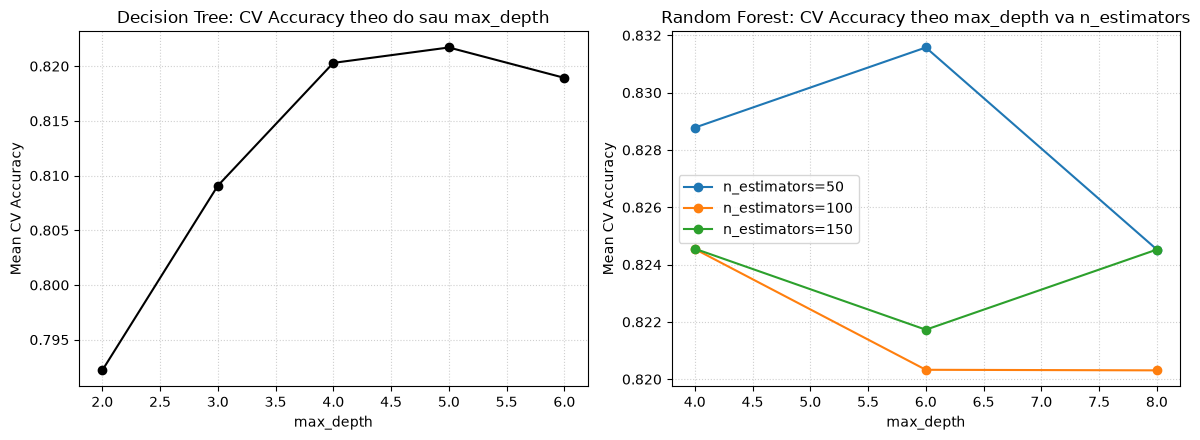

In [10]:
# GridSearchCV Decision Tree
param_grid_dt_ti = {
    'max_depth': [2, 3, 4, 5, 6],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
grid_dt_ti = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid_dt_ti, cv=5, scoring='accuracy')
grid_dt_ti.fit(X_tr_ti, y_tr_ti)
best_dt_ti = grid_dt_ti.best_estimator_
print('DT Best params:', grid_dt_ti.best_params_, 'CV Score:', round(grid_dt_ti.best_score_, 4))

# GridSearchCV Random Forest
param_grid_rf_ti = {
    'n_estimators': [50, 100, 150],
    'max_depth': [4, 6, 8],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [2, 4],
    'max_features': ['sqrt']
}
grid_rf_ti = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf_ti, cv=5, scoring='accuracy')
grid_rf_ti.fit(X_tr_ti, y_tr_ti)
best_rf_ti = grid_rf_ti.best_estimator_
print('RF Best params:', grid_rf_ti.best_params_, 'CV Score:', round(grid_rf_ti.best_score_, 4))

# Bieu do danh gia qua trinh tuning Titanic
cv_dt_ti = pd.DataFrame(grid_dt_ti.cv_results_)
dt_ti_depth_scores = cv_dt_ti.groupby('param_max_depth')['mean_test_score'].max()
cv_rf_ti = pd.DataFrame(grid_rf_ti.cv_results_)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(dt_ti_depth_scores.index, dt_ti_depth_scores.values, '-o', color='black')
axes[0].set_xlabel('max_depth')
axes[0].set_ylabel('Mean CV Accuracy')
axes[0].set_title('Decision Tree: CV Accuracy theo do sau max_depth')
axes[0].grid(True, linestyle=':', alpha=0.6)

for nest in [50, 100, 150]:
    sub = cv_rf_ti[cv_rf_ti['param_n_estimators'] == nest]
    sub_grouped = sub.groupby('param_max_depth')['mean_test_score'].max()
    axes[1].plot(sub_grouped.index, sub_grouped.values, '-o', label=f'n_estimators={nest}')
axes[1].set_xlabel('max_depth')
axes[1].set_ylabel('Mean CV Accuracy')
axes[1].set_title('Random Forest: CV Accuracy theo max_depth va n_estimators')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('../figures/2_1_3_titanic_tuning.png', dpi=300, bbox_inches='tight')
plt.show()


### 4. Đánh giá trên tập kiểm tra & Confusion Matrix


=== Classification Report: Decision Tree (Tuned) ===
              precision    recall  f1-score   support

     Tu vong       0.77      0.88      0.82       110
    Song sot       0.75      0.58      0.66        69

    accuracy                           0.77       179
   macro avg       0.76      0.73      0.74       179
weighted avg       0.76      0.77      0.76       179

=== Classification Report: Random Forest (Tuned) ===
              precision    recall  f1-score   support

     Tu vong       0.79      0.94      0.85       110
    Song sot       0.85      0.59      0.70        69

    accuracy                           0.80       179
   macro avg       0.82      0.77      0.78       179
weighted avg       0.81      0.80      0.80       179



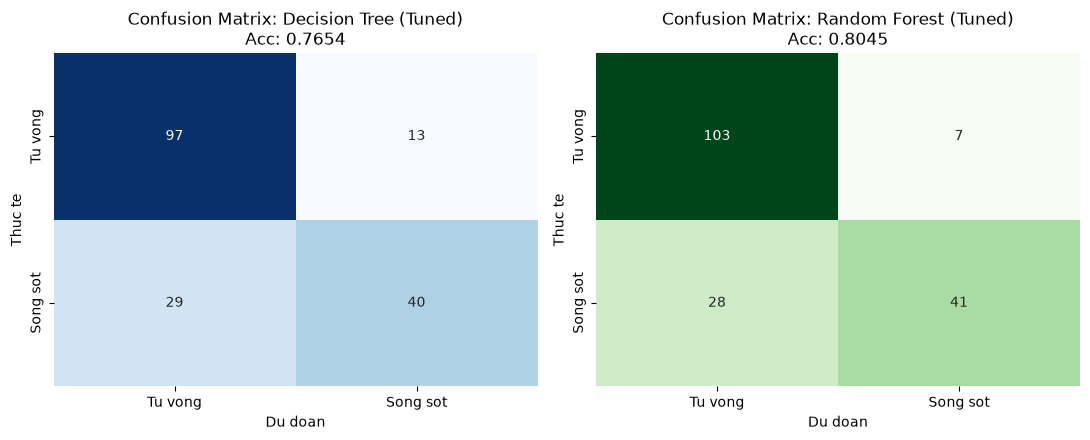

In [11]:
print("=== Classification Report: Decision Tree (Tuned) ===")
print(classification_report(y_te_ti, best_dt_ti.predict(X_te_ti), target_names=['Tu vong', 'Song sot']))

print("=== Classification Report: Random Forest (Tuned) ===")
print(classification_report(y_te_ti, best_rf_ti.predict(X_te_ti), target_names=['Tu vong', 'Song sot']))

# Bieu do Confusion Matrix 2 mo hinh
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
cm_dt = confusion_matrix(y_te_ti, best_dt_ti.predict(X_te_ti))
cm_rf = confusion_matrix(y_te_ti, best_rf_ti.predict(X_te_ti))

sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=['Tu vong', 'Song sot'], yticklabels=['Tu vong', 'Song sot'])
axes[0].set_title(f"Confusion Matrix: Decision Tree (Tuned)\nAcc: {accuracy_score(y_te_ti, best_dt_ti.predict(X_te_ti)):.4f}")
axes[0].set_xlabel('Du doan')
axes[0].set_ylabel('Thuc te')

sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', ax=axes[1], cbar=False,
            xticklabels=['Tu vong', 'Song sot'], yticklabels=['Tu vong', 'Song sot'])
axes[1].set_title(f"Confusion Matrix: Random Forest (Tuned)\nAcc: {accuracy_score(y_te_ti, best_rf_ti.predict(X_te_ti)):.4f}")
axes[1].set_xlabel('Du doan')
axes[1].set_ylabel('Thuc te')

plt.tight_layout()
plt.savefig('../figures/2_1_3_titanic_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()


### 5. Trực quan hóa cây quyết định tốt nhất & Feature Importance


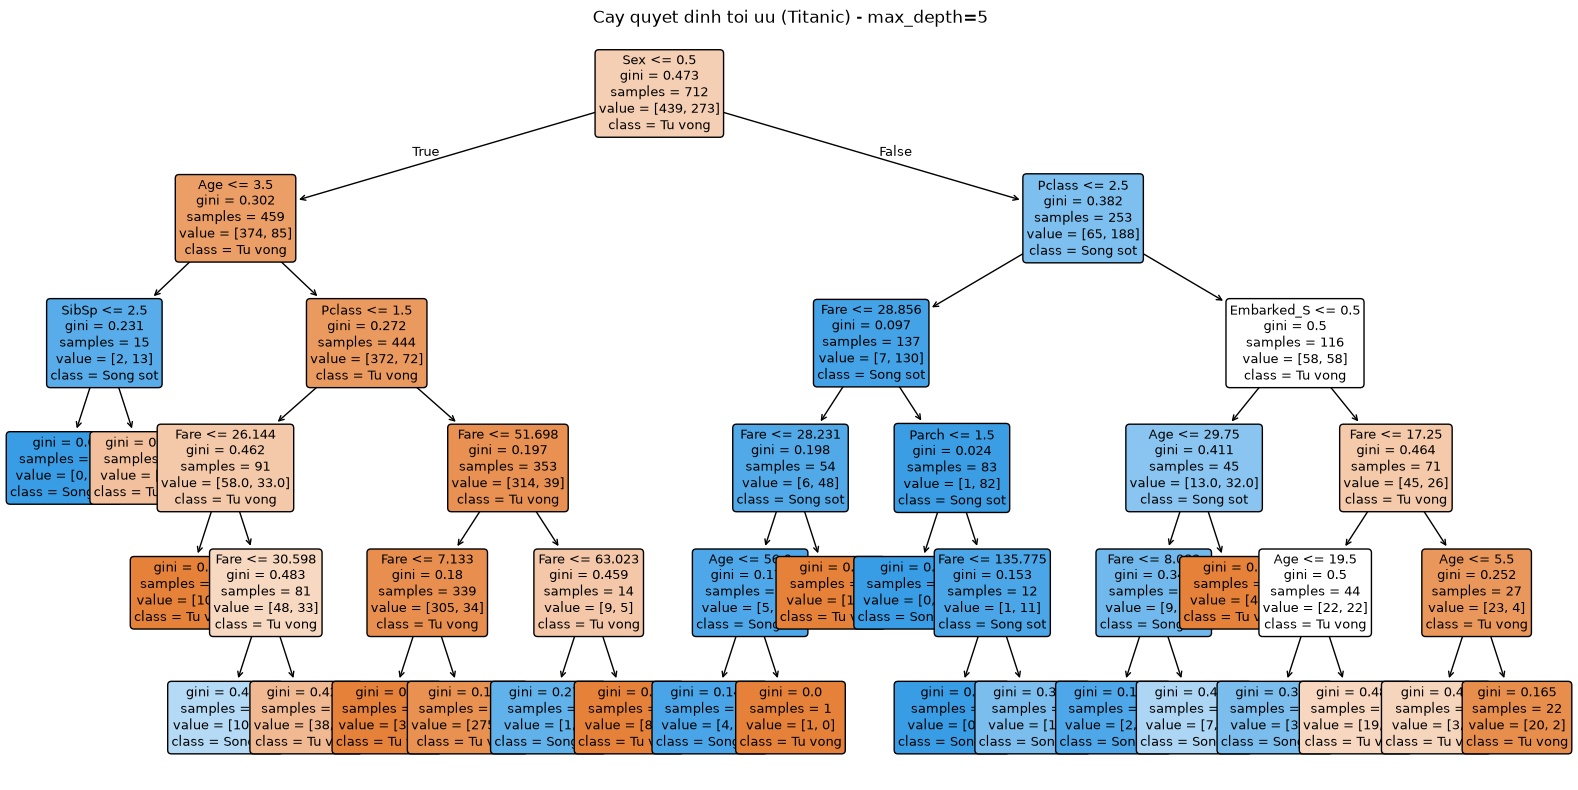

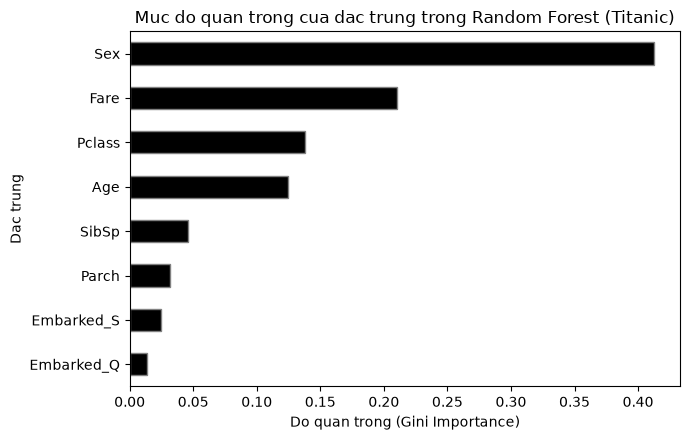

In [12]:
# Ve cay quyet dinh Titanic toi uu
plt.figure(figsize=(16, 8), dpi=400)
plot_tree(
    best_dt_ti, feature_names=features_ti, class_names=['Tu vong', 'Song sot'],
    filled=True, rounded=True, fontsize=9
)
plt.title(f"Cay quyet dinh toi uu (Titanic) - max_depth={best_dt_ti.max_depth}")
plt.tight_layout()
plt.savefig('../figures/2_1_3_titanic_best_tree.png', dpi=400, bbox_inches='tight')
plt.show()

# Feature Importance Titanic
fi_ti = pd.Series(best_rf_ti.feature_importances_, index=features_ti).sort_values(ascending=True)
plt.figure(figsize=(7, 4.5))
fi_ti.plot(kind='barh', color='black', edgecolor='gray')
plt.xlabel('Do quan trong (Gini Importance)')
plt.ylabel('Dac trung')
plt.title('Muc do quan trong cua dac trung trong Random Forest (Titanic)')
plt.tight_layout()
plt.savefig('../figures/2_1_3_titanic_rf_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()


---
## 2.1.4. BÀI TẬP THỰC HÀNH 2: DỰ ĐOÁN BỆNH TIỂU ĐƯỜNG (PIMA INDIANS DIABETES)

### 1. Khám phá & Tiền xử lý dữ liệu Diabetes


In [13]:
di_path = '../data/diabetes.csv' if os.path.exists('../data/diabetes.csv') else 'Lab05_ThucHanhBaiToanPhanLop/data/diabetes.csv'
diabetes_raw = pd.read_csv(di_path)
print('Kich thuoc Diabetes goc:', diabetes_raw.shape)
print('Phan bo nhan Outcome:')
print(diabetes_raw['Outcome'].value_counts())

# Chia train/test truoc de tranh Data Leakage
cols_zero = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
features_di = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
X_raw_di = diabetes_raw[features_di]
y_di = diabetes_raw['Outcome']

X_tr_di, X_te_di, y_tr_di, y_te_di = train_test_split(
    X_raw_di, y_di, test_size=0.2, random_state=42, stratify=y_di
)
X_tr_di = X_tr_di.copy()
X_te_di = X_te_di.copy()

for col in cols_zero:
    X_tr_di[col] = X_tr_di[col].replace(0, np.nan)
    med = X_tr_di[col].median()
    X_tr_di[col] = X_tr_di[col].fillna(med)
    X_te_di[col] = X_te_di[col].replace(0, np.nan)
    X_te_di[col] = X_te_di[col].fillna(med)

print('X_train:', X_tr_di.shape, 'X_test:', X_te_di.shape)


Kich thuoc Diabetes goc: (768, 9)
Phan bo nhan Outcome:
Outcome
0    500
1    268
Name: count, dtype: int64
X_train: (614, 8) X_test: (154, 8)


### 2. Xây dựng Baseline Decision Tree và Random Forest


In [14]:
dt_base_di = DecisionTreeClassifier(random_state=42)
dt_base_di.fit(X_tr_di, y_tr_di)
print('DT Baseline Train Accuracy:', round(accuracy_score(y_tr_di, dt_base_di.predict(X_tr_di)), 4))
print('DT Baseline Test Accuracy :', round(accuracy_score(y_te_di, dt_base_di.predict(X_te_di)), 4))

rf_base_di = RandomForestClassifier(random_state=42)
rf_base_di.fit(X_tr_di, y_tr_di)
print('RF Baseline Train Accuracy:', round(accuracy_score(y_tr_di, rf_base_di.predict(X_tr_di)), 4))
print('RF Baseline Test Accuracy :', round(accuracy_score(y_te_di, rf_base_di.predict(X_te_di)), 4))


DT Baseline Train Accuracy: 1.0
DT Baseline Test Accuracy : 0.6818
RF Baseline Train Accuracy: 1.0
RF Baseline Test Accuracy : 0.7662


### 3. Tối ưu hóa siêu tham số bằng GridSearchCV


DT Best params: {'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 2} CV F1: 0.592
RF Best params: {'max_depth': 7, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 50} CV F1: 0.6401


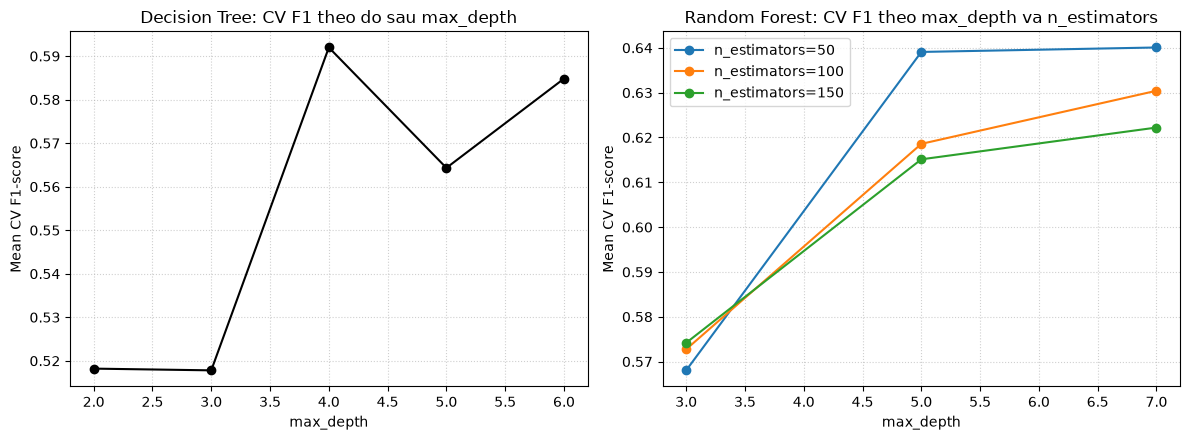

In [15]:
param_grid_dt_di = {
    'max_depth': [2, 3, 4, 5, 6],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
grid_dt_di = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid_dt_di, cv=5, scoring='f1')
grid_dt_di.fit(X_tr_di, y_tr_di)
best_dt_di = grid_dt_di.best_estimator_
print('DT Best params:', grid_dt_di.best_params_, 'CV F1:', round(grid_dt_di.best_score_, 4))

param_grid_rf_di = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 5, 7],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [2, 4],
    'max_features': ['sqrt']
}
grid_rf_di = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf_di, cv=5, scoring='f1')
grid_rf_di.fit(X_tr_di, y_tr_di)
best_rf_di = grid_rf_di.best_estimator_
print('RF Best params:', grid_rf_di.best_params_, 'CV F1:', round(grid_rf_di.best_score_, 4))

# Bieu do danh gia qua trinh tuning Diabetes
cv_dt_di = pd.DataFrame(grid_dt_di.cv_results_)
dt_di_depth_scores = cv_dt_di.groupby('param_max_depth')['mean_test_score'].max()
cv_rf_di = pd.DataFrame(grid_rf_di.cv_results_)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(dt_di_depth_scores.index, dt_di_depth_scores.values, '-o', color='black')
axes[0].set_xlabel('max_depth')
axes[0].set_ylabel('Mean CV F1-score')
axes[0].set_title('Decision Tree: CV F1 theo do sau max_depth')
axes[0].grid(True, linestyle=':', alpha=0.6)

for nest in [50, 100, 150]:
    sub = cv_rf_di[cv_rf_di['param_n_estimators'] == nest]
    sub_grouped = sub.groupby('param_max_depth')['mean_test_score'].max()
    axes[1].plot(sub_grouped.index, sub_grouped.values, '-o', label=f'n_estimators={nest}')
axes[1].set_xlabel('max_depth')
axes[1].set_ylabel('Mean CV F1-score')
axes[1].set_title('Random Forest: CV F1 theo max_depth va n_estimators')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('../figures/2_1_4_diabetes_tuning.png', dpi=300, bbox_inches='tight')
plt.show()


### 4. Đánh giá trên tập kiểm tra & Confusion Matrix


=== Classification Report: Decision Tree (Tuned) ===
                precision    recall  f1-score   support

Khong mac benh       0.83      0.84      0.84       100
      Mac benh       0.70      0.69      0.69        54

      accuracy                           0.79       154
     macro avg       0.76      0.76      0.76       154
  weighted avg       0.78      0.79      0.79       154

=== Classification Report: Random Forest (Tuned) ===
                precision    recall  f1-score   support

Khong mac benh       0.78      0.87      0.82       100
      Mac benh       0.69      0.54      0.60        54

      accuracy                           0.75       154
     macro avg       0.73      0.70      0.71       154
  weighted avg       0.75      0.75      0.74       154



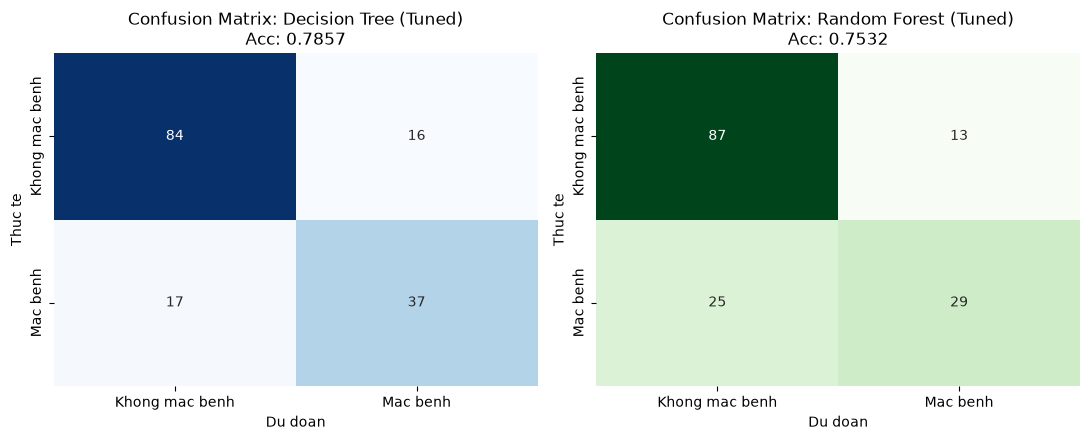

In [16]:
print("=== Classification Report: Decision Tree (Tuned) ===")
print(classification_report(y_te_di, best_dt_di.predict(X_te_di), target_names=['Khong mac benh', 'Mac benh']))

print("=== Classification Report: Random Forest (Tuned) ===")
print(classification_report(y_te_di, best_rf_di.predict(X_te_di), target_names=['Khong mac benh', 'Mac benh']))

# Bieu do Confusion Matrix Diabetes
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
cm_dt_di = confusion_matrix(y_te_di, best_dt_di.predict(X_te_di))
cm_rf_di = confusion_matrix(y_te_di, best_rf_di.predict(X_te_di))

sns.heatmap(cm_dt_di, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=['Khong mac benh', 'Mac benh'], yticklabels=['Khong mac benh', 'Mac benh'])
axes[0].set_title(f"Confusion Matrix: Decision Tree (Tuned)\nAcc: {accuracy_score(y_te_di, best_dt_di.predict(X_te_di)):.4f}")
axes[0].set_xlabel('Du doan')
axes[0].set_ylabel('Thuc te')

sns.heatmap(cm_rf_di, annot=True, fmt='d', cmap='Greens', ax=axes[1], cbar=False,
            xticklabels=['Khong mac benh', 'Mac benh'], yticklabels=['Khong mac benh', 'Mac benh'])
axes[1].set_title(f"Confusion Matrix: Random Forest (Tuned)\nAcc: {accuracy_score(y_te_di, best_rf_di.predict(X_te_di)):.4f}")
axes[1].set_xlabel('Du doan')
axes[1].set_ylabel('Thuc te')

plt.tight_layout()
plt.savefig('../figures/2_1_4_diabetes_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()


### 5. Trực quan hóa cây quyết định tối ưu & Feature Importance


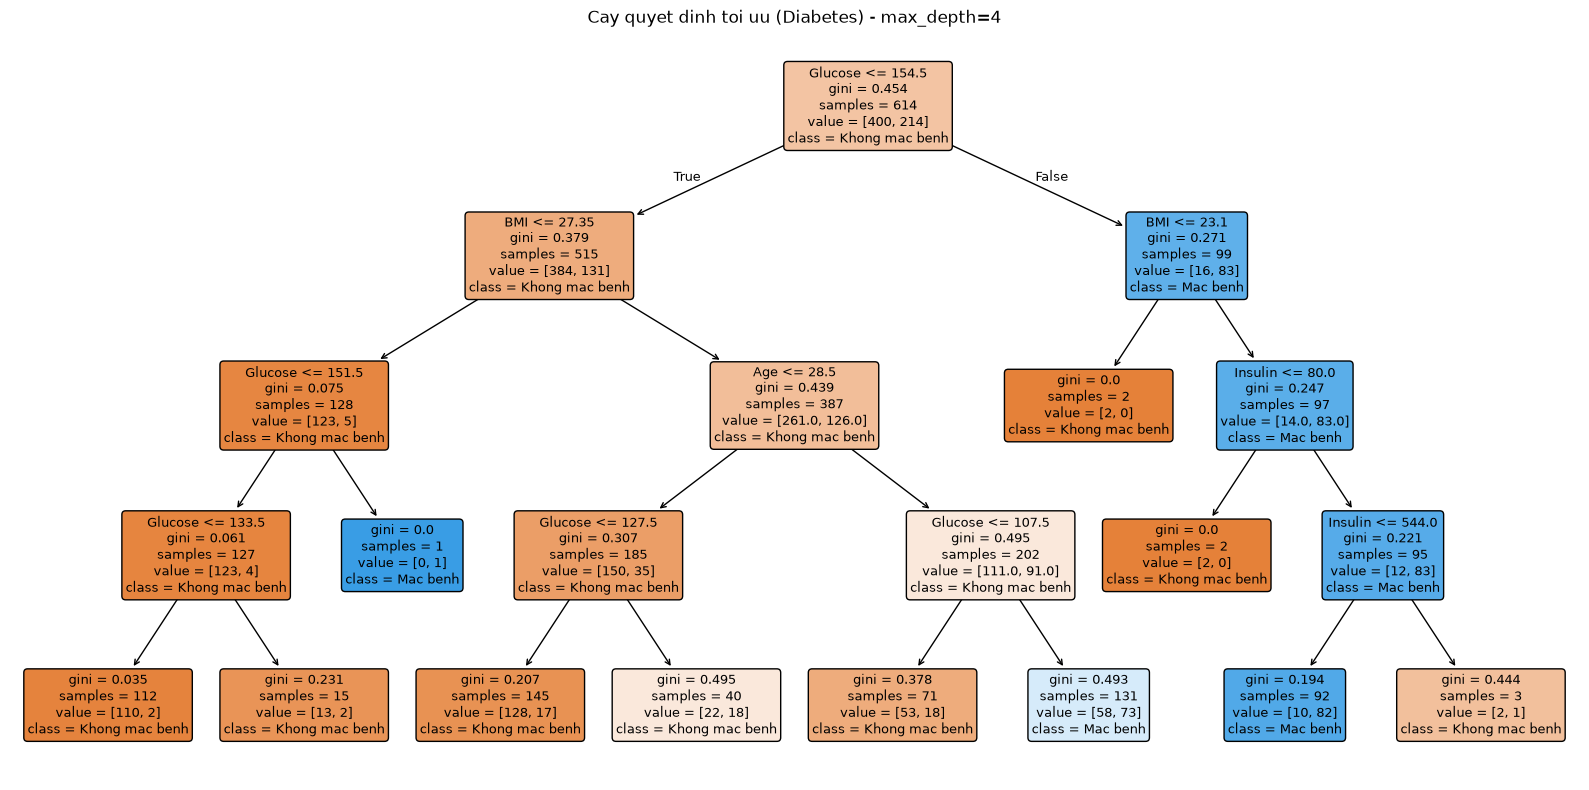

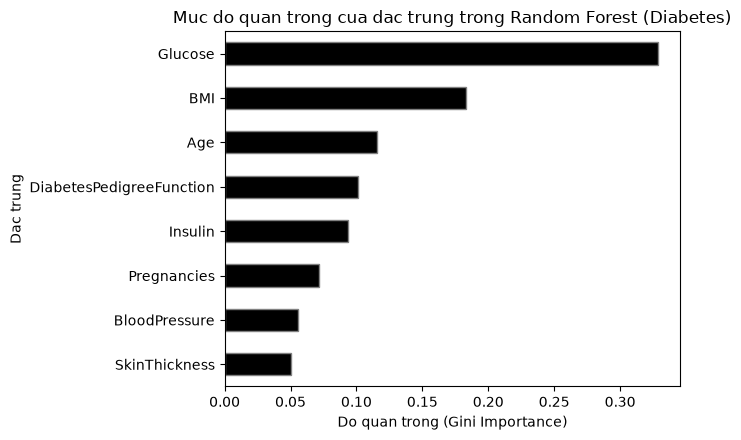

In [17]:
# Ve cay quyet dinh Diabetes
plt.figure(figsize=(16, 8), dpi=400)
plot_tree(
    best_dt_di, feature_names=features_di, class_names=['Khong mac benh', 'Mac benh'],
    filled=True, rounded=True, fontsize=9
)
plt.title(f"Cay quyet dinh toi uu (Diabetes) - max_depth={best_dt_di.max_depth}")
plt.tight_layout()
plt.savefig('../figures/2_1_4_diabetes_best_tree.png', dpi=400, bbox_inches='tight')
plt.show()

# Feature Importance Diabetes
fi_di = pd.Series(best_rf_di.feature_importances_, index=features_di).sort_values(ascending=True)
plt.figure(figsize=(7, 4.5))
fi_di.plot(kind='barh', color='black', edgecolor='gray')
plt.xlabel('Do quan trong (Gini Importance)')
plt.ylabel('Dac trung')
plt.title('Muc do quan trong cua dac trung trong Random Forest (Diabetes)')
plt.tight_layout()
plt.savefig('../figures/2_1_4_diabetes_rf_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()


### 6. Bảng tổng hợp so sánh trực diện Decision Tree và Random Forest


In [18]:
summary_metrics = pd.read_csv('../figures/summary_metrics_2_1.csv') if os.path.exists('../figures/summary_metrics_2_1.csv') else pd.read_csv('Lab05_ThucHanhBaiToanPhanLop/figures/summary_metrics_2_1.csv')
print(summary_metrics.to_string(index=False))


                 Model  Train Acc  Test Acc  Precision   Recall  F1-Score  ROC-AUC
 DT Baseline (Titanic)   0.983146  0.821229   0.784615 0.739130  0.761194 0.801515
    DT Tuned (Titanic)   0.863764  0.765363   0.754717 0.579710  0.655738 0.788208
 RF Baseline (Titanic)   0.983146  0.810056   0.786885 0.695652  0.738462 0.843544
    RF Tuned (Titanic)   0.876404  0.804469   0.854167 0.594203  0.700855 0.845125
DT Baseline (Diabetes)   1.000000  0.681818   0.553191 0.481481  0.514851 0.635741
   DT Tuned (Diabetes)   0.794788  0.785714   0.698113 0.685185  0.691589 0.788704
RF Baseline (Diabetes)   1.000000  0.766234   0.695652 0.592593  0.640000 0.821019
   RF Tuned (Diabetes)   0.894137  0.753247   0.690476 0.537037  0.604167 0.811852


### Nhận xét về hiện tượng quá khớp:
1. Decision Tree Baseline: Khi không bị giới hạn độ sâu và số mẫu tại nút lá, cây quyết định học thuộc lòng toàn bộ dữ liệu huấn luyện, dẫn đến độ chính xác huấn luyện đạt tới 98.17% ở Titanic và 100% ở Diabetes. Tuy nhiên trên tập kiểm tra, độ chính xác giảm xuống lần lượt 82.12% và 68.18%. Khoảng chênh lệch lớn giữa train và test chứng minh hiện tượng quá khớp.
2. Hiệu quả của GridSearchCV: Giới hạn max_depth ở mức 4 đến 5 và đặt ngưỡng số mẫu tối thiểu tại nút lá giúp tỉa bớt các nhánh học nhiễu. Độ chính xác huấn luyện giảm về mức 79% đến 86%, trong khi độ chính xác và F1-score trên tập kiểm định tăng, đặc biệt trên tập Diabetes F1-score tăng từ 0.51 lên 0.69.
3. Ưu thế của Random Forest: Random Forest kết hợp nhiều cây con độc lập được huấn luyện trên các tập mẫu ngẫu nhiên và tập đặc trưng ngẫu nhiên. Việc lấy trung bình dự đoán từ nhiều cây giúp giảm mạnh phương sai tổng thể, giữ độ chệch ở mức thấp và kiểm soát quá khớp. Random Forest duy trì ROC-AUC trên 0.80 đến 0.83 và dự đoán ổn định hơn cây quyết định đơn lẻ.
